# Expected Goals Prediction in Football Using Machine Learning

**IT461 – Machine Learning**  
**Section 72597 – Group 10**

## Project Overview

This project develops machine learning models to estimate the probability that a **non-penalty football shot results in a goal**. The problem is formulated as a supervised binary classification task, where each shot is labelled as either a **goal (`1`)** or **non-goal (`0`)**. The predicted probability of the goal class represents the shot's **Expected Goals (xG)** value.

The project uses **StatsBomb Open Data** and compares two feature configurations:

- **Location-only:** shot distance and shot opening angle derived from the original `[x, y]` shot coordinates.
- **Context-aware:** distance and angle together with shot body part, shooting technique, first-time status, shot type, play pattern, and pressure status.

Two machine learning methods are evaluated: **Logistic Regression** and **Support Vector Machine (SVM)**. By comparing the location-only and context-aware configurations, the project investigates whether contextual shot information improves goal-probability estimation beyond shot location alone.

The notebook follows the full machine learning workflow, including data cleaning, feature engineering, preprocessing, model training, and evaluation. The StatsBomb-provided `shot_statsbomb_xg` value is excluded from model training and retained only as an external benchmark for later comparison.

### Running the Notebook

The notebook should be executed **from top to bottom** so that each stage produces the variables required by the following sections. The raw shot dataset is loaded from the project data directory, after which all cleaning, feature engineering, preprocessing, training, and evaluation steps are performed sequentially.

## Setup and Dependencies

The following packages are required to run the notebook. They provide tools for data manipulation, numerical computation, visualization, preprocessing, and machine learning.

In [1]:
%pip install -q pandas numpy matplotlib mplsoccer scikit-learn scipy

Note: you may need to restart the kernel to use updated packages.


# 1. Data Cleaning and Preparation

In [2]:
import pandas as pd

# Load the raw dataset
df = pd.read_csv("../data/raw/statsbomb_non_penalty_shots_raw.csv")

# Preserve a copy of the original dataset
df_raw = df.copy()

print("Dataset shape:", df.shape)
display(df.head())
df.info()


Dataset shape: (12374, 13)


,match_id,id,team,player,location,shot_body_part,shot_technique,shot_first_time,shot_type,play_pattern,under_pressure,shot_outcome,shot_statsbomb_xg
0,3939988,20be3941-09d4-4073-98f7-a56806520e3e,Mexico,Orbelín Pineda Alvarado,"[96.5, 57.7]",Right Foot,Normal,NaN,Open Play,Regular Play,NaN,Blocked,0.011882
1,3939988,1e67056c-794f-4f1a-98b1-12a347a1dfb6,Mexico,César Saúl Huerta Valera,"[98.2, 37.5]",Left Foot,Half Volley,True,Open Play,Regular Play,True,Off T,0.057859
2,3939988,9265e407-3347-4c35-8e52-6b3811cf48f7,Mexico,Orbelín Pineda Alvarado,"[102.0, 57.9]",Right Foot,Normal,NaN,Open Play,Regular Play,NaN,Blocked,0.016745
3,3939988,955126e9-b026-4a35-a255-d4bf81b545f7,Ecuador,Moisés Isaac Caicedo Corozo,"[94.3, 30.3]",Right Foot,Normal,NaN,Free Kick,From Free Kick,NaN,Blocked,0.053783
4,3939988,3b4bdfd2-d26f-4244-bf75-aff5a7a5ff76,Ecuador,Ray Kendry Páez Andrade,"[92.6, 34.4]",Left Foot,Half Volley,True,Open Play,From Free Kick,NaN,Saved,0.017840


<class 'pandas.DataFrame'>
RangeIndex: 12374 entries, 0 to 12373
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   match_id           12374 non-null  int64  
 1   id                 12374 non-null  str    
 2   team               12374 non-null  str    
 3   player             12374 non-null  str    
 4   location           12374 non-null  str    
 5   shot_body_part     12374 non-null  str    
 6   shot_technique     12374 non-null  str    
 7   shot_first_time    3880 non-null   object 
 8   shot_type          12374 non-null  str    
 9   play_pattern       12374 non-null  str    
 10  under_pressure     3096 non-null   object 
 11  shot_outcome       12374 non-null  str    
 12  shot_statsbomb_xg  12374 non-null  float64
dtypes: float64(1), int64(1), object(2), str(9)
memory usage: 1.2+ MB


## 1.1 Handling Missing Values

Missing values were identified in the **shot_first_time** and **under_pressure** attributes. Since these attributes represent Boolean flags, missing values are treated as False, indicating that the corresponding condition was not recorded as present. This approach preserves all shot records without removing potentially useful training data.

In [3]:
# Check missing values in each column
print("Missing values before cleaning:")
print(df.isnull().sum())


Missing values before cleaning:
match_id                0
id                      0
team                    0
player                  0
location                0
shot_body_part          0
shot_technique          0
shot_first_time      8494
shot_type               0
play_pattern            0
under_pressure       9278
shot_outcome            0
shot_statsbomb_xg       0
dtype: int64


In [4]:
# Replace missing values with False
df["shot_first_time"] = df["shot_first_time"].fillna(False)
df["under_pressure"] = df["under_pressure"].fillna(False)


print("Missing values after cleaning:")
print(df.isnull().sum())

# Check the data types
print(df[["shot_first_time", "under_pressure"]].dtypes)


Missing values after cleaning:
match_id             0
id                   0
team                 0
player               0
location             0
shot_body_part       0
shot_technique       0
shot_first_time      0
shot_type            0
play_pattern         0
under_pressure       0
shot_outcome         0
shot_statsbomb_xg    0
dtype: int64
shot_first_time    object
under_pressure     object
dtype: object


## 1.2 Creating the Binary Target Variable

The **shot_outcome** column contains different shot outcomes. Since this project is a binary classification task, a new target variable named goal is created, where 1 represents a goal and 0 represents any non-goal outcome.

In [5]:

# Check the original shot outcomes
print("Original shot outcomes:")
print(df["shot_outcome"].value_counts())

# binary target variable
df["goal"] = (df["shot_outcome"] == "Goal").astype(int)

# the new target variable
print("\nBinary target distribution:")
print(df["goal"].value_counts())

# Display sample records
display(df[["shot_outcome", "goal"]].head())


Original shot outcomes:
shot_outcome
Off T               3932
Blocked             3079
Saved               2940
Goal                1383
Wayward              672
Post                 281
Saved Off Target      53
Saved to Post         34
Name: count, dtype: int64

Binary target distribution:
goal
0    10991
1     1383
Name: count, dtype: int64


,shot_outcome,goal
0,Blocked,0
1,Off T,0
2,Blocked,0
3,Blocked,0
4,Saved,0


## 1.3 Data Quality Verification

After handling missing values and creating the binary target variable, the dataset is checked for data types, duplicate records, and target class distribution. These checks ensure data consistency and help identify potential issues before model training.

In [6]:
# Check data types
print("Data types:")
print(df.dtypes)

# Check duplicate rows and shot IDs
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate shot IDs:", df["id"].duplicated().sum())

# Check class distribution
print("\nClass distribution (counts):")
print(df["goal"].value_counts())

print("\nClass distribution (percentages):")
print((df["goal"].value_counts(normalize=True) * 100).round(2))

# Check final dataset shape
print("\nDataset shape:", df.shape)


Data types:
match_id               int64
id                       str
team                     str
player                   str
location                 str
shot_body_part           str
shot_technique           str
shot_first_time       object
shot_type                str
play_pattern             str
under_pressure        object
shot_outcome             str
shot_statsbomb_xg    float64
goal                   int64
dtype: object

Duplicate rows: 0
Duplicate shot IDs: 0

Class distribution (counts):
goal
0    10991
1     1383
Name: count, dtype: int64

Class distribution (percentages):
goal
0    88.82
1    11.18
Name: proportion, dtype: float64

Dataset shape: (12374, 14)


## 1.4 Reusable Data-Cleaning Function

A reusable function is created to combine the preprocessing steps into a single process. The function handles missing Boolean values and creates the binary target variable while preserving the original dataset. This ensures that the same cleaning steps can be applied consistently whenever needed.

In [7]:
def clean_shot_data(raw_df):
    # Create a copy to preserve the original dataset
    cleaned_df = raw_df.copy()

    # Handle missing values
    cleaned_df["shot_first_time"] = cleaned_df["shot_first_time"].fillna(False)
    cleaned_df["under_pressure"] = cleaned_df["under_pressure"].fillna(False)

    # Create the binary target variable
    cleaned_df["goal"] = (cleaned_df["shot_outcome"] == "Goal").astype(int)

    return cleaned_df


# Apply the cleaning function to the original dataset
df_clean = clean_shot_data(df_raw)

print("Cleaned dataset shape:", df_clean.shape)
print("Total missing values:", df_clean.isnull().sum().sum())
print("Duplicate shot IDs:", df_clean["id"].duplicated().sum())

display(df_clean.head())


Cleaned dataset shape: (12374, 14)
Total missing values: 0
Duplicate shot IDs: 0


,match_id,id,team,player,location,shot_body_part,shot_technique,shot_first_time,shot_type,play_pattern,under_pressure,shot_outcome,shot_statsbomb_xg,goal
0,3939988,20be3941-09d4-4073-98f7-a56806520e3e,Mexico,Orbelín Pineda Alvarado,"[96.5, 57.7]",Right Foot,Normal,False,Open Play,Regular Play,False,Blocked,0.011882,0
1,3939988,1e67056c-794f-4f1a-98b1-12a347a1dfb6,Mexico,César Saúl Huerta Valera,"[98.2, 37.5]",Left Foot,Half Volley,True,Open Play,Regular Play,True,Off T,0.057859,0
2,3939988,9265e407-3347-4c35-8e52-6b3811cf48f7,Mexico,Orbelín Pineda Alvarado,"[102.0, 57.9]",Right Foot,Normal,False,Open Play,Regular Play,False,Blocked,0.016745,0
3,3939988,955126e9-b026-4a35-a255-d4bf81b545f7,Ecuador,Moisés Isaac Caicedo Corozo,"[94.3, 30.3]",Right Foot,Normal,False,Free Kick,From Free Kick,False,Blocked,0.053783,0
4,3939988,3b4bdfd2-d26f-4244-bf75-aff5a7a5ff76,Ecuador,Ray Kendry Páez Andrade,"[92.6, 34.4]",Left Foot,Half Volley,True,Open Play,From Free Kick,False,Saved,0.017840,0


# 2. Feature Engineering and Preprocessing

## 2.1 Shot Location Processing

The raw `location` attribute stores the position of each shot as an `[x, y]` coordinate pair. To calculate spatial features from these coordinates, the location values are first converted into a numerical format and separated into individual `x` and `y` components.

These coordinates are then used to calculate the shot's **distance from goal** and **opening angle to the goalposts** in the following subsections.

In [8]:
import ast

# Convert the stored location string into a Python list
df_features = df_clean.copy()

df_features["location"] = df_features["location"].apply(ast.literal_eval)

# Separate the location into numeric x and y coordinates
df_features["x"] = df_features["location"].apply(lambda loc: loc[0])
df_features["y"] = df_features["location"].apply(lambda loc: loc[1])

# Inspect the result
display(df_features[["location", "x", "y"]].head())

,location,x,y
0,"[96.5, 57.7]",96.5,57.7
1,"[98.2, 37.5]",98.2,37.5
2,"[102.0, 57.9]",102.0,57.9
3,"[94.3, 30.3]",94.3,30.3
4,"[92.6, 34.4]",92.6,34.4


### Understanding the StatsBomb Coordinate System

The `location` attribute represents the position from which each shot was taken using StatsBomb's `[x, y]` pitch coordinates. The pitch is represented on a **120 × 80 coordinate system**, where `x` describes the position along the length of the pitch and `y` describes the position across its width. Shots are represented relative to the attacking direction, with the centre of the opponent's goal located at **(120, 40)**.

The figure below illustrates this coordinate system and shows the location of an example shot from the dataset at **(96.5, 57.7)**. These coordinates will be used to derive the **distance to goal** and **shot angle**, which form the numerical features of the location-only model.

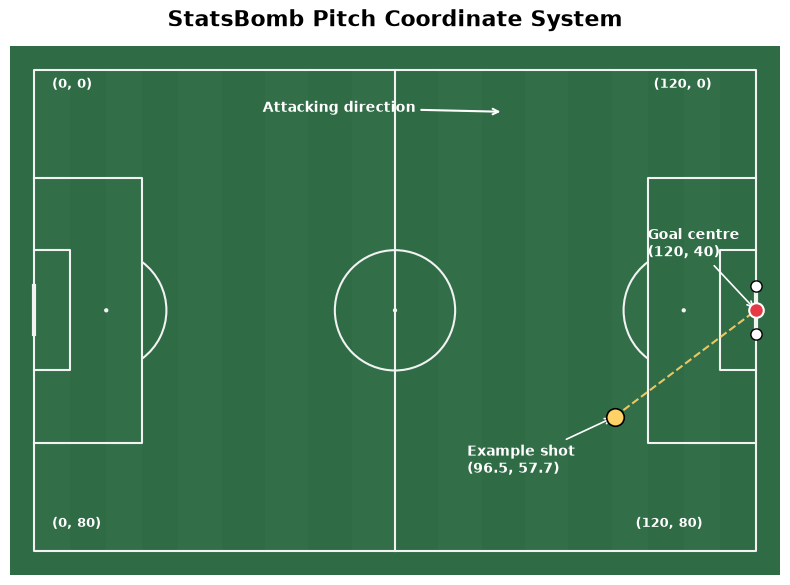

In [9]:
from mplsoccer import Pitch
import matplotlib.pyplot as plt

# Example shot from the dataset
example_x = 96.5
example_y = 57.7

# Create a clean StatsBomb pitch
pitch = Pitch(
    pitch_type="statsbomb",
    pitch_color="#2f6b45",
    line_color="#f2f2f2",
    linewidth=1.5,
    stripe=True,
    stripe_color="#326f49"
)

fig, ax = pitch.draw(figsize=(8, 6))

# Coordinate labels at the four corners
corner_labels = [
    (0, 0, "(0, 0)", (3, 3)),
    (120, 0, "(120, 0)", (103, 3)),
    (0, 80, "(0, 80)", (3, 76)),
    (120, 80, "(120, 80)", (100, 76))
]

for x, y, label, text_pos in corner_labels:
    pitch.annotate(
        label,
        (x, y),
        ax=ax,
        xytext=text_pos,
        fontsize=9,
        color="white",
        fontweight="bold"
    )

# Goalposts
pitch.scatter(
    [120, 120],
    [36, 44],
    ax=ax,
    s=65,
    color="white",
    edgecolor="black",
    zorder=5
)

# Goal centre
pitch.scatter(
    120, 40,
    ax=ax,
    s=110,
    color="#e63946",
    edgecolor="white",
    linewidth=1.5,
    zorder=6
)

pitch.annotate(
    "Goal centre\n(120, 40)",
    (120, 40),
    ax=ax,
    xytext=(102, 31),
    fontsize=10,
    color="white",
    fontweight="bold",
    arrowprops=dict(
        arrowstyle="->",
        color="white",
        lw=1.2
    )
)

# Example shot
pitch.scatter(
    example_x,
    example_y,
    ax=ax,
    s=160,
    color="#ffd166",
    edgecolor="black",
    linewidth=1.2,
    zorder=7
)

pitch.annotate(
    "Example shot\n(96.5, 57.7)",
    (example_x, example_y),
    ax=ax,
    xytext=(72, 67),
    fontsize=10,
    color="white",
    fontweight="bold",
    arrowprops=dict(
        arrowstyle="->",
        color="white",
        lw=1.2
    )
)

# Dashed line from the shot to the goal centre
pitch.lines(
    example_x, example_y,
    120, 40,
    ax=ax,
    color="#ffd166",
    linestyle="--",
    linewidth=1.5,
    alpha=0.9,
    zorder=4
)

# Show attacking direction
pitch.annotate(
    "Attacking direction",
    (78, 7),
    ax=ax,
    xytext=(38, 7),
    fontsize=10,
    color="white",
    fontweight="bold",
    arrowprops=dict(
        arrowstyle="->",
        color="white",
        lw=1.5
    )
)

ax.set_title(
    "StatsBomb Pitch Coordinate System",
    fontsize=16,
    fontweight="bold",
    pad=14
)

plt.show()

## 2.2 Distance to Goal

Shot distance measures how far the shot location is from the centre of the attacking goal. In the StatsBomb coordinate system, event locations are standardized so that the team performing the action attacks toward `x = 120`. Therefore, all shots in this dataset are measured relative to the attacking goal centred at **(120, 40)**; it is not necessary to switch the goal location to `(0, 40)` for shots taken by the opposing team.

Using the shot coordinates `(x, y)`, the Euclidean distance to the centre of the goal is calculated as:

$$
\text{distance} = \sqrt{(120-x)^2 + (40-y)^2}
$$

A smaller distance represents a shot taken closer to goal, while a larger distance represents a shot taken farther away.
The resulting distance is expressed in StatsBomb coordinate units rather than metres.

In [10]:
import numpy as np

# Calculate Euclidean distance from each shot to the centre of the goal
df_features["distance"] = np.sqrt(
    (120 - df_features["x"])**2 +
    (40 - df_features["y"])**2
)

# Inspect the result
display(
    df_features[
        ["location", "x", "y", "distance"]
    ].head()
)

,location,x,y,distance
0,"[96.5, 57.7]",96.5,57.7,29.420061
1,"[98.2, 37.5]",98.2,37.5,21.942880
2,"[102.0, 57.9]",102.0,57.9,25.385232
3,"[94.3, 30.3]",94.3,30.3,27.469620
4,"[92.6, 34.4]",92.6,34.4,27.966408


## 2.3 Shot Angle

Shot angle describes **how wide the goal appears to the player from the location of the shot**. It does not represent the direction in which the ball was kicked.

The attacking goal extends approximately from `(120, 36)` to `(120, 44)` in the StatsBomb coordinate system. From each shot location, two imaginary lines can be drawn: one to each goalpost. The angle between these two lines is the **shot opening angle**.

A shot taken from a central position generally produces a larger angle because the two goalposts appear farther apart. A shot taken from a wide position generally produces a smaller angle because the goal appears narrower.

The angle is calculated by finding the direction from the shot location to each goalpost using `arctan2`, then taking the absolute difference between the two directions. The resulting angle is stored in **radians** for use by the machine learning models.

Distance and angle provide complementary information: distance describes **how far** the shot is from goal, while angle describes **how wide the goal appears** from that position.

In [11]:
# Calculate the direction from each shot to the two goalposts
angle_post_1 = np.arctan2(
    36 - df_features["y"],
    120 - df_features["x"]
)

angle_post_2 = np.arctan2(
    44 - df_features["y"],
    120 - df_features["x"]
)

# Shot opening angle in radians
df_features["angle"] = np.abs(
    angle_post_2 - angle_post_1
)

# Use the smaller angle if wrap-around occurs
df_features["angle"] = np.minimum(
    df_features["angle"],
    2 * np.pi - df_features["angle"]
)

# Optional more readable version
df_features["angle_degrees"] = np.degrees(df_features["angle"])

display(
    df_features[
        ["location", "distance", "angle", "angle_degrees"]
    ].head()
)

,location,distance,angle,angle_degrees
0,"[96.5, 57.7]",29.420061,0.217786,12.478239
1,"[98.2, 37.5]",21.942880,0.358472,20.538912
2,"[102.0, 57.9]",25.385232,0.225261,12.906488
3,"[94.3, 30.3]",27.469620,0.271498,15.555714
4,"[92.6, 34.4]",27.966408,0.278672,15.966729


## 2.4 Engineered Feature Validation

The engineered distance and angle features were checked for missing, infinite, and invalid values before model training. No missing or infinite values were found.

Distance values are non-negative, while shot angles fall within the valid range of 0 to π radians. Extremely large opening angles can occur for shots taken very close to or on the goal line between the goalposts. For example, an angle of π radians (180°) represents an extreme case where the two goalposts lie in opposite directions from the shot location.

In [12]:
# Validate engineered numerical features
print("Missing distance values:", df_features["distance"].isna().sum())
print("Missing angle values:", df_features["angle"].isna().sum())

print("Infinite distance values:", np.isinf(df_features["distance"]).sum())
print("Infinite angle values:", np.isinf(df_features["angle"]).sum())

print("\nDistance range:")
print(df_features["distance"].min(), "to", df_features["distance"].max())

print("\nAngle range (radians):")
print(df_features["angle"].min(), "to", df_features["angle"].max())

print("\nAngle range (degrees):")
print(
    df_features["angle_degrees"].min(),
    "to",
    df_features["angle_degrees"].max()
)

Missing distance values: 0
Missing angle values: 0
Infinite distance values: 0
Infinite angle values: 0

Distance range:
0.9219544457292917 to 89.82944951406526

Angle range (radians):
0.0010255552031301907 to 3.141592653589793

Angle range (degrees):
0.05875998479704176 to 180.0


## 2.5 Feature Set Definition

Two feature configurations are prepared for the experiments.

The **location-only feature set** contains only the engineered shot distance and shot opening angle. This provides a simple baseline based solely on where the shot was taken.

The **context-aware feature set** contains distance and angle together with contextual shot characteristics: body part, technique, first-time status, shot type, play pattern, and pressure status.

The target variable for both feature sets is `goal`, where `1` represents a goal and `0` represents a non-goal.

Identifiers such as `match_id`, `id`, `team`, and `player` are not used as model inputs. The original `shot_outcome` is also excluded because it is the source used to create the target variable. `shot_statsbomb_xg` is retained only for later benchmarking and is not used during model training.

In [13]:
# Define the two model feature sets

location_features = [
    "distance",
    "angle"
]

context_features = [
    "distance",
    "angle",
    "shot_body_part",
    "shot_technique",
    "shot_first_time",
    "shot_type",
    "play_pattern",
    "under_pressure"
]

target = "goal"

# Create feature matrices and target vector
X_location = df_features[location_features].copy()
X_context = df_features[context_features].copy()
y = df_features[target].copy()

# Inspect the resulting datasets
print("Location-only feature set shape:", X_location.shape)
print("Context-aware feature set shape:", X_context.shape)
print("Target shape:", y.shape)

print("\nLocation-only features:")
print(X_location.columns.tolist())

print("\nContext-aware features:")
print(X_context.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

Location-only feature set shape: (12374, 2)
Context-aware feature set shape: (12374, 8)
Target shape: (12374,)

Location-only features:
['distance', 'angle']

Context-aware features:
['distance', 'angle', 'shot_body_part', 'shot_technique', 'shot_first_time', 'shot_type', 'play_pattern', 'under_pressure']

Target distribution:
goal
0    10991
1     1383
Name: count, dtype: int64


## 2.6 Train-Test Split

The dataset is divided into **80% training data and 20% testing data**. This split provides enough observations for model training while still reserving a sufficiently large unseen test set for reliable final evaluation.

Because the target variable is imbalanced, with substantially fewer goals than non-goals, **stratified splitting** is used so that the goal and non-goal proportions remain approximately the same in both the training and testing subsets.

A fixed `random_state = 42` is used to make the split reproducible. The same training and testing observations are used for both the location-only and context-aware feature sets so that their performance can be compared fairly.

The split is performed **before fitting any encoders or scalers**. This ensures that preprocessing parameters are learned only from the training data and prevents information from the test set from leaking into the training process.

In [14]:
from sklearn.model_selection import train_test_split

# Split row indices so both feature sets use the exact same observations
train_idx, test_idx = train_test_split(
    df_features.index,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Location-only feature set
X_location_train = X_location.loc[train_idx].copy()
X_location_test = X_location.loc[test_idx].copy()

# Context-aware feature set
X_context_train = X_context.loc[train_idx].copy()
X_context_test = X_context.loc[test_idx].copy()

# Target variable
y_train = y.loc[train_idx].copy()
y_test = y.loc[test_idx].copy()

# Display split sizes
print("Training samples:", len(train_idx))
print("Testing samples:", len(test_idx))

# Display class distributions
print("\nTraining target distribution:")
print(y_train.value_counts())
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting target distribution:")
print(y_test.value_counts())
print((y_test.value_counts(normalize=True) * 100).round(2))

# Keep StatsBomb xG values aligned with the test set for later benchmarking
statsbomb_xg_test = df_features.loc[test_idx, "shot_statsbomb_xg"].copy()

Training samples: 9899
Testing samples: 2475

Training target distribution:
goal
0    8793
1    1106
Name: count, dtype: int64
goal
0    88.83
1    11.17
Name: proportion, dtype: float64

Testing target distribution:
goal
0    2198
1     277
Name: count, dtype: int64
goal
0    88.81
1    11.19
Name: proportion, dtype: float64


## 2.7 Encoding and Scaling

The model inputs contain numerical, categorical, and Boolean features, so each data type is preprocessed appropriately.

The numerical features, `distance` and `angle`, are standardized using `StandardScaler`. These features have substantially different numerical ranges, and both Logistic Regression and SVM can be affected by feature scale. Standardization prevents a feature from having greater influence simply because it is represented using larger numerical values and also supports stable model optimization.

The categorical features, `shot_body_part`, `shot_technique`, `shot_type`, and `play_pattern`, are transformed using one-hot encoding. This converts each category into binary indicator features without introducing an artificial numerical ordering between categories. Unknown categories encountered in the test data are ignored so that preprocessing remains robust to categories that were not observed during training.

The Boolean features, `shot_first_time` and `under_pressure`, are converted to binary numerical values, where `False = 0` and `True = 1`.

All preprocessing transformations are fitted using the **training data only** and are then applied unchanged to the test data. This prevents information from the test set from influencing model training.

In [15]:
# Feature groups used by the preprocessing pipelines

numerical_features = [
    "distance",
    "angle"
]

categorical_features = [
    "shot_body_part",
    "shot_technique",
    "shot_type",
    "play_pattern"
]

boolean_features = [
    "shot_first_time",
    "under_pressure"
]

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)
print("Boolean features:", boolean_features)

Numerical features: ['distance', 'angle']
Categorical features: ['shot_body_part', 'shot_technique', 'shot_type', 'play_pattern']
Boolean features: ['shot_first_time', 'under_pressure']


In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer

# Convert Boolean values to 0/1
boolean_transformer = FunctionTransformer(
    lambda x: x.astype(int),
    feature_names_out="one-to-one"
)

# Location-only preprocessing:
# scale distance and angle
location_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features)
    ]
)

# Context-aware preprocessing:
# scale numerical features, one-hot encode categories,
# and convert Boolean values to 0/1
context_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "bool",
            boolean_transformer,
            boolean_features
        )
    ]
)

print("Preprocessing pipelines created successfully.")

Preprocessing pipelines created successfully.


## 2.8 Applying the Preprocessing Pipelines

The preprocessing pipelines are fitted using only the training data. The fitted transformations are then applied to both the training and test sets.

For the location-only feature set, `StandardScaler` learns the mean and standard deviation of `distance` and `angle` from the training data.

For the context-aware feature set, the numerical scaler and categorical encoder are also fitted only on the training observations. The test set is transformed using these already learned preprocessing parameters without refitting.

This procedure prevents information from the test set from influencing the training process and avoids data leakage.

In [17]:
# Fit preprocessing on the training data and transform both train and test sets

# Location-only data
X_location_train_processed = location_preprocessor.fit_transform(
    X_location_train
)

X_location_test_processed = location_preprocessor.transform(
    X_location_test
)

# Context-aware data
X_context_train_processed = context_preprocessor.fit_transform(
    X_context_train
)

X_context_test_processed = context_preprocessor.transform(
    X_context_test
)

print("Location-only:")
print("Training shape:", X_location_train_processed.shape)
print("Testing shape:", X_location_test_processed.shape)

print("\nContext-aware:")
print("Training shape:", X_context_train_processed.shape)
print("Testing shape:", X_context_test_processed.shape)


Location-only:
Training shape: (9899, 2)
Testing shape: (2475, 2)

Context-aware:
Training shape: (9899, 28)
Testing shape: (2475, 28)


In [18]:
# Inspect the generated feature names
location_feature_names = location_preprocessor.get_feature_names_out()
context_feature_names = context_preprocessor.get_feature_names_out()

print("Processed location-only features:")
print(location_feature_names)

print("\nNumber of processed context-aware features:")
print(len(context_feature_names))

print("\nProcessed context-aware features:")
for feature in context_feature_names:
    print(feature)

Processed location-only features:
['num__distance' 'num__angle']

Number of processed context-aware features:
28

Processed context-aware features:
num__distance
num__angle
cat__shot_body_part_Head
cat__shot_body_part_Left Foot
cat__shot_body_part_Other
cat__shot_body_part_Right Foot
cat__shot_technique_Backheel
cat__shot_technique_Diving Header
cat__shot_technique_Half Volley
cat__shot_technique_Lob
cat__shot_technique_Normal
cat__shot_technique_Overhead Kick
cat__shot_technique_Volley
cat__shot_type_Corner
cat__shot_type_Free Kick
cat__shot_type_Kick Off
cat__shot_type_Open Play
cat__play_pattern_From Corner
cat__play_pattern_From Counter
cat__play_pattern_From Free Kick
cat__play_pattern_From Goal Kick
cat__play_pattern_From Keeper
cat__play_pattern_From Kick Off
cat__play_pattern_From Throw In
cat__play_pattern_Other
cat__play_pattern_Regular Play
bool__shot_first_time
bool__under_pressure


## 2.9 Preprocessing Validation

The transformed datasets are checked before model training to ensure that preprocessing was applied successfully.

The training and test sets must contain the same number of processed features, and the transformed values must not contain missing or infinite values. The scaled numerical features are also inspected to confirm that standardization was fitted correctly on the training data.

The processed feature names are retained to make the transformed representation interpretable and to verify the categorical and Boolean transformations.

In [19]:
from scipy import sparse

# Helper function for checking both dense and sparse transformed data
def validate_processed_data(name, X):
    if sparse.issparse(X):
        values = X.data
    else:
        values = np.asarray(X)

    print(name)
    print("Shape:", X.shape)
    print("Missing values:", np.isnan(values).sum())
    print("Infinite values:", np.isinf(values).sum())
    print()


validate_processed_data(
    "Location-only training data",
    X_location_train_processed
)

validate_processed_data(
    "Location-only test data",
    X_location_test_processed
)

validate_processed_data(
    "Context-aware training data",
    X_context_train_processed
)

validate_processed_data(
    "Context-aware test data",
    X_context_test_processed
)

Location-only training data
Shape: (9899, 2)
Missing values: 0
Infinite values: 0

Location-only test data
Shape: (2475, 2)
Missing values: 0
Infinite values: 0

Context-aware training data
Shape: (9899, 28)
Missing values: 0
Infinite values: 0

Context-aware test data
Shape: (2475, 28)
Missing values: 0
Infinite values: 0



In [20]:
# Check the scaled location-only training features
print("Scaled training feature means:")
print(
    dict(
        zip(
            location_feature_names,
            np.round(X_location_train_processed.mean(axis=0), 4)
        )
    )
)

print("\nScaled training feature standard deviations:")
print(
    dict(
        zip(
            location_feature_names,
            np.round(X_location_train_processed.std(axis=0), 4)
        )
    )
)

Scaled training feature means:
{'num__distance': np.float64(-0.0), 'num__angle': np.float64(-0.0)}

Scaled training feature standard deviations:
{'num__distance': np.float64(1.0), 'num__angle': np.float64(1.0)}


## 2.10 Preprocessing Summary

The preprocessing stage produced two model-ready feature configurations:

- **Location-only:** standardized `distance` and `angle`.
- **Context-aware:** standardized numerical features, one-hot encoded categorical features, and binary Boolean features.

The same stratified 80/20 train-test split is used for both feature configurations to ensure fair comparison. All preprocessing transformations are fitted using training data only, and the final processed datasets contain no missing or infinite values.

For later model training and cross-validation, the reusable preprocessing objects `location_preprocessor` and `context_preprocessor` should be incorporated directly into the model pipelines so that preprocessing is refitted independently within each training fold and data leakage is avoided.

In [21]:
print("Final objects for modelling:")
print("- location_preprocessor")
print("- context_preprocessor")
print("- X_location_train, X_location_test")
print("- X_context_train, X_context_test")
print("- y_train, y_test")
print("- statsbomb_xg_test")

Final objects for modelling:
- location_preprocessor
- context_preprocessor
- X_location_train, X_location_test
- X_context_train, X_context_test
- y_train, y_test
- statsbomb_xg_test
